In [1]:
import os
import torch
from botorch import fit_gpytorch_mll
import botorch_tool
import copy
from botorch.sampling.normal import SobolQMCNormalSampler
from botorch.utils.transforms import unnormalize, normalize, standardize
import numpy as np 

torch.set_default_dtype(torch.float64)
MC_SAMPLES = 512
sampler = SobolQMCNormalSampler(sample_shape=torch.Size([MC_SAMPLES]))

from botorch.test_functions.multi_objective import DTLZ7
tkwargs = {
    "dtype": torch.double,
    "device": torch.device("cuda" if torch.cuda.is_available() else "cpu"),
}
problem = DTLZ7(dim = 3, negate=True, noise_std = 0.4)

ININITIAL_SAMPLING_NUM = 2

np.random.seed(42)
torch.manual_seed(42)

In [2]:
data_total = []
for repeat in range(16):
    # make sure the two comparison start from the same initial condition
    np.random.seed(repeat*1000)
    torch.manual_seed(repeat*1000)
    # initial random sampling
    train_observation_x = torch.cat([torch.rand(ININITIAL_SAMPLING_NUM, 2), 
                                     torch.randint(21, (ININITIAL_SAMPLING_NUM, 1))/20], dim=-1)
    train_observation_y = problem(train_observation_x)
    print(train_observation_x)
    print(train_observation_y)
    
    # begin the optimization loop 
    for budget in range(100):
        print(f"{repeat}_{budget} \r")
        # normalize training x to [0,1]
        train_x = train_observation_x
        # standarize train_y
        train_y = standardize(train_observation_y)
        # get models and train the models
        mll, model = botorch_tool.tools.initialize_model(train_x = train_x, train_obj = train_y, cat_dims = [2])
        fit_gpytorch_mll(mll)
        # define the boundaries for the optimization problem 
        bounds = torch.stack([torch.zeros(train_x.shape[1]), torch.ones(train_x.shape[1])])
        categorical_values = {2: np.linspace(0,1,21).tolist()}
        key_set = list(categorical_values.keys())
        value_set = list(categorical_values.values())
        fixed_features_list = []
        for i in value_set[0]:
            fixed_features_list.append({key_set[0] : i})
        # get the candidate 
        MC_SAMPLES = 512
        sampler = SobolQMCNormalSampler(sample_shape=torch.Size([MC_SAMPLES]))
        candidate = botorch_tool.tools.optimize_qnehvi_and_get_observation(
            model = model, 
            train_x = train_x, 
            ref_point = [0,0],
            sampler = sampler,
            cat_dims = [2], 
            fixed_features_list = fixed_features_list)
        train_observation_x = torch.concat((train_observation_x,candidate))
        train_observation_y = torch.concat((train_observation_y,problem(candidate)))
        
    data_total.append(
        [train_observation_x,train_observation_y]
    )

tensor([[0.9701, 0.7078, 0.2000],
        [0.4594, 0.9207, 0.6000]])
tensor([[ -1.0342, -10.6876],
        [ -0.1462, -18.0783]])
0_0 
0_1 
0_2 
0_3 
0_4 
0_5 
0_6 
0_7 
0_8 
0_9 
0_10 
0_11 
0_12 


/home/yibin/anaconda3/envs/botorch/lib/python3.11/site-packages/botorch/optim/optimize.py:359: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[NumericalWarning('A not p.d., added jitter of 1.0e-08 to the diagonal'), OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL_TERMINATION_IN_LNSRCH.'), NumericalWarning('A not p.d., added jitter of 1.0e-08 to the diagonal')]
Trying again with a new set of initial conditions.
  warnings.warn(first_warn_msg, RuntimeWarning)


0_13 
0_14 
0_15 


/home/yibin/anaconda3/envs/botorch/lib/python3.11/site-packages/botorch/optim/initializers.py:403: BadInitialCandidatesWarning: Unable to find non-zero acquisition function values - initial conditions are being selected randomly.
  warnings.warn(


0_16 


/home/yibin/anaconda3/envs/botorch/lib/python3.11/site-packages/botorch/optim/initializers.py:403: BadInitialCandidatesWarning: Unable to find non-zero acquisition function values - initial conditions are being selected randomly.
  warnings.warn(
/home/yibin/anaconda3/envs/botorch/lib/python3.11/site-packages/botorch/optim/initializers.py:403: BadInitialCandidatesWarning: Unable to find non-zero acquisition function values - initial conditions are being selected randomly.
  warnings.warn(


... (2,676 outputs left out)

15_98 


/home/yibin/anaconda3/envs/botorch/lib/python3.11/site-packages/linear_operator/utils/cholesky.py:40: NumericalWarning: A not p.d., added jitter of 1.0e-08 to the diagonal
  warnings.warn(
/home/yibin/anaconda3/envs/botorch/lib/python3.11/site-packages/botorch/optim/initializers.py:403: BadInitialCandidatesWarning: Unable to find non-zero acquisition function values - initial conditions are being selected randomly.
  warnings.warn(
/home/yibin/anaconda3/envs/botorch/lib/python3.11/site-packages/botorch/optim/initializers.py:403: BadInitialCandidatesWarning: Unable to find non-zero acquisition function values - initial conditions are being selected randomly.
  warnings.warn(
/home/yibin/anaconda3/envs/botorch/lib/python3.11/site-packages/botorch/optim/initializers.py:403: BadInitialCandidatesWarning: Unable to find non-zero acquisition function values - initial conditions are being selected randomly.
  warnings.warn(
/home/yibin/anaconda3/envs/botorch/lib/python3.11/site-packages/botorc

15_99 


/home/yibin/anaconda3/envs/botorch/lib/python3.11/site-packages/linear_operator/utils/cholesky.py:40: NumericalWarning: A not p.d., added jitter of 1.0e-08 to the diagonal
  warnings.warn(
/home/yibin/anaconda3/envs/botorch/lib/python3.11/site-packages/botorch/optim/initializers.py:403: BadInitialCandidatesWarning: Unable to find non-zero acquisition function values - initial conditions are being selected randomly.
  warnings.warn(
/home/yibin/anaconda3/envs/botorch/lib/python3.11/site-packages/botorch/optim/initializers.py:403: BadInitialCandidatesWarning: Unable to find non-zero acquisition function values - initial conditions are being selected randomly.
  warnings.warn(
/home/yibin/anaconda3/envs/botorch/lib/python3.11/site-packages/botorch/optim/initializers.py:403: BadInitialCandidatesWarning: Unable to find non-zero acquisition function values - initial conditions are being selected randomly.
  warnings.warn(
/home/yibin/anaconda3/envs/botorch/lib/python3.11/site-packages/botorc

In [3]:
# read in data

In [4]:
import pickle
with open(f"./qnehvi.pkl", 'wb') as fp:
    pickle.dump(data_total, fp)

In [5]:
f = open('./qnehvi.pkl', 'rb')
data2 = pickle.load(f)  

f = open('./qehvi.pkl', 'rb')
data3 = pickle.load(f)  

In [6]:
from botorch.utils.multi_objective.box_decompositions.dominated import (
    DominatedPartitioning,
)
from botorch.utils.multi_objective.pareto import is_non_dominated

hvs_list_total = []
for i in range(16):
    train_observation_y = data2[i][1]
    hvs_list = []
    for i in range(len(train_observation_y)-ININITIAL_SAMPLING_NUM):
        bd = DominatedPartitioning(ref_point=problem.ref_point, 
                                   Y = train_observation_y[0:ININITIAL_SAMPLING_NUM+i])
        volume = bd.compute_hypervolume().item()
        hvs_list.append(volume)
    hvs_list_total.append(hvs_list)

hvs_list_total2 = []
for i in range(16):
    train_observation_y = data3[i][1]
    hvs_list = []
    for i in range(len(train_observation_y)-ININITIAL_SAMPLING_NUM):
        bd = DominatedPartitioning(ref_point=problem.ref_point, 
                                   Y = train_observation_y[0:ININITIAL_SAMPLING_NUM+i])
        volume = bd.compute_hypervolume().item()
        hvs_list.append(volume)
    hvs_list_total2.append(hvs_list)    

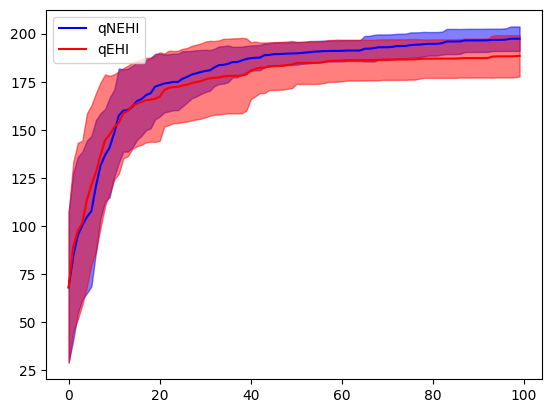

In [7]:
from matplotlib import pyplot as plt
hvs_list_total = np.array(hvs_list_total)
hvs_list_total2 = np.array(hvs_list_total2)

plt.plot(hvs_list_total.mean(axis = 0), color = "blue", label = "qNEHI")
plt.fill_between(np.arange(len(hvs_list_total.mean(axis = 0))), 
                 hvs_list_total.mean(axis = 0) + hvs_list_total.std(axis = 0), 
                 hvs_list_total.mean(axis = 0) - hvs_list_total.std(axis = 0),
                 color='blue', alpha=0.5)

plt.plot(hvs_list_total2.mean(axis = 0), color = "red", label = "qEHI")

plt.fill_between(np.arange(len(hvs_list_total2.mean(axis = 0))), 
                 hvs_list_total2.mean(axis = 0) + hvs_list_total2.std(axis = 0), 
                 hvs_list_total2.mean(axis = 0) - hvs_list_total2.std(axis = 0),
                 color='red', alpha=0.5)
plt.legend()